# Упрощённый анализ факторов цены товара

В ноутбуке оценивается одна регрессионная модель по данным Retail Price. Вопрос: как общая цена товара связана с числом покупателей, ценой третьего конкурента и весом? Анализ показывает связи, но не доказывает причинное влияние.

В таблице 676 наблюдений по 52 товарам. Один товар встречается в разные месяцы, поэтому для проверки коэффициентов используются кластерные стандартные ошибки по `product_id`.

## 1. Подготовка данных

Для модели нужны общая цена, число покупателей, цена конкурента, вес и идентификатор товара. `unit_price` и `qty` не включаются, поскольку их произведение приблизительно формирует `total_price`; `lag_price` почти совпадает с `unit_price`. Признак `s` исключён, так как его смысл описан неоднозначно. Все переменные, логарифмы которых рассчитываются, положительны.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

data = pd.read_csv(Path('retail_price.csv'))
columns = ['total_price', 'customers', 'comp_3', 'product_weight_g', 'product_id']
model_data = data[columns].dropna().copy()
numeric_columns = ['total_price', 'customers', 'comp_3', 'product_weight_g']
assert (model_data[numeric_columns] > 0).all().all()

for column in numeric_columns:
    model_data[f'log_{column}'] = np.log(model_data[column])

print(f'Наблюдений: {len(model_data)}')
print(f'Товарных групп: {model_data.product_id.nunique()}')
print(f'Строк с пропусками в выбранных переменных исключено: {len(data) - len(model_data)}')

Наблюдений: 676
Товарных групп: 52
Строк с пропусками в выбранных переменных исключено: 0


## 2. Краткое описание данных

Сначала посмотрим на среднее, медиану и диапазон исходных значений, затем сравним распределение цены до и после логарифмирования. Также проверим парные корреляции логарифмированных признаков; это описательная характеристика, а не полная диагностика мультиколлинеарности.

In [2]:
descriptive = model_data[numeric_columns].agg(['mean', 'median', 'min', 'max']).T
descriptive.index = ['Общая цена', 'Число покупателей', 'Цена конкурента 3', 'Вес товара, г']
descriptive.columns = ['Среднее', 'Медиана', 'Минимум', 'Максимум']
display(descriptive.round(2))

,Среднее,Медиана,Минимум,Максимум
Общая цена,1422.71,807.89,19.9,12095.00
Число покупателей,81.03,62.00,1.0,339.00
Цена конкурента 3,84.18,59.90,19.9,255.61
"Вес товара, г",1847.50,950.00,100.0,9750.00


### Распределение общей цены

Гистограммы показывают исходную цену и её натуральный логарифм. Логарифмирование сжимает большие значения; этот график помогает описать данные, но сам по себе не проверяет все предпосылки регрессии.

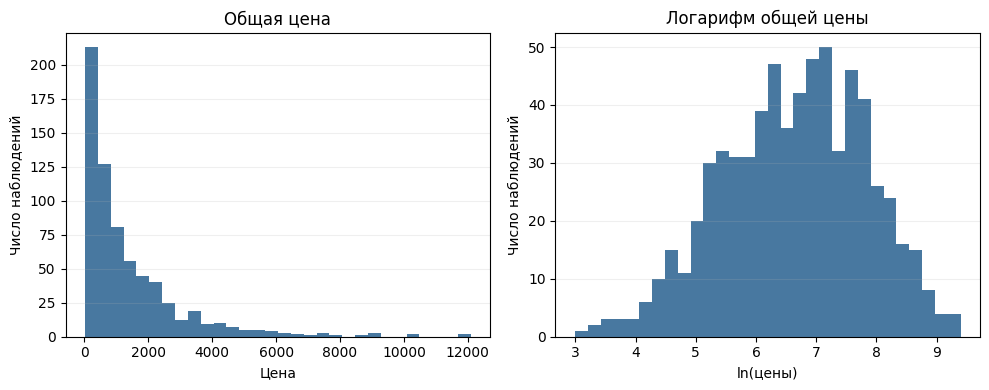

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(model_data['total_price'], bins=30, color='#286090', alpha=0.85)
axes[0].set_title('Общая цена')
axes[0].set_xlabel('Цена')
axes[0].set_ylabel('Число наблюдений')
axes[0].grid(axis='y', alpha=0.2)
axes[1].hist(model_data['log_total_price'], bins=30, color='#286090', alpha=0.85)
axes[1].set_title('Логарифм общей цены')
axes[1].set_xlabel('ln(цены)')
axes[1].set_ylabel('Число наблюдений')
axes[1].grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig('price_distribution_simple.png', dpi=160, bbox_inches='tight')
plt.show()

### Парные корреляции признаков

Матрица ниже показывает корреляции Пирсона между тремя логарифмированными признаками. Небольшие парные корреляции не являются полной проверкой отсутствия мультиколлинеарности.

In [4]:
predictor_columns = ['log_customers', 'log_comp_3', 'log_product_weight_g']
correlation_matrix = model_data[predictor_columns].corr()
correlation_labels = ['Число покупателей', 'Цена конкурента 3', 'Вес товара']
correlation_display = correlation_matrix.copy()
correlation_display.index = correlation_labels
correlation_display.columns = correlation_labels
display(correlation_display.round(4))
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
)
max_pairwise_correlation = upper_triangle.abs().max().max()
print(f'Максимальная парная корреляция по модулю: {max_pairwise_correlation:.4f}')

,Число покупателей,Цена конкурента 3,Вес товара
Число покупателей,1.0000,-0.0405,0.0297
Цена конкурента 3,-0.0405,1.0000,0.0164
Вес товара,0.0297,0.0164,1.0000


Максимальная парная корреляция по модулю: 0.0405


## 3. Оценка модели и статистические проверки

Оценивается модель `ln(total_price) ~ ln(customers) + ln(comp_3) + ln(product_weight_g)`. Группировка стандартных ошибок по товару учитывает, что наблюдения одного товара могут быть похожи. Для каждого коэффициента проверяется гипотеза `β = 0`; дополнительно F-тест проверяет, равны ли нулю все три коэффициента одновременно. Уровень значимости — 5%.

In [5]:
product_groups = pd.factorize(model_data['product_id'])[0]
formula = 'log_total_price ~ log_customers + log_comp_3 + log_product_weight_g'
ols_result = smf.ols(formula, data=model_data).fit()
cluster_result = ols_result.get_robustcov_results(
    cov_type='cluster',
    groups=product_groups,
    use_correction=True,
    df_correction=True,
    use_t=True,
)

restriction = np.zeros((3, len(cluster_result.params)))
restriction[:, 1:] = np.eye(3)
joint_test = cluster_result.f_test(restriction)

confidence_intervals = cluster_result.conf_int(alpha=0.05)
results = pd.DataFrame({
    'Коэффициент': cluster_result.params,
    'Кластерная SE': cluster_result.bse,
    't': cluster_result.tvalues,
    'p-value': cluster_result.pvalues,
    'Нижняя граница 95%': confidence_intervals[:, 0],
    'Верхняя граница 95%': confidence_intervals[:, 1],
}, index=ols_result.model.exog_names)
results_display = results.round(4)
results_display['p-value'] = results['p-value'].map(lambda value: f'{value:.3g}')
display(results_display)
print(
    f'Совместный тест: F(3, {model_data.product_id.nunique() - 1}) = '
    f'{float(np.asarray(joint_test.fvalue).squeeze()):.2f}, '
    f'p-value = {float(np.asarray(joint_test.pvalue).squeeze()):.3g}'
)
print(f'R²: {ols_result.rsquared:.3f}')
print(f'Скорректированный R²: {ols_result.rsquared_adj:.3f}')
print(f'Число степеней свободы для кластерного t-критерия: {model_data.product_id.nunique() - 1}')

,Коэффициент,Кластерная SE,t,p-value,Нижняя граница 95%,Верхняя граница 95%
Intercept,1.3381,0.6718,1.9919,0.0517,-0.0105,2.6867
log_customers,0.5406,0.0604,8.9572,4.8e-12,0.4194,0.6618
log_comp_3,0.5260,0.1410,3.7309,0.00048,0.2430,0.8091
log_product_weight_g,0.1260,0.0728,1.7307,0.0896,-0.0202,0.2721


Совместный тест: F(3, 51) = 46.45, p-value = 1.29e-14
R²: 0.257
Скорректированный R²: 0.254
Число степеней свободы для кластерного t-критерия: 51


### Полученные результаты

| Признак | Коэффициент | p-value | 95%-ный интервал | Вывод при 5% |
|---|---:|---:|---:|---|
| Число покупателей | 0,541 | 4,80 · 10⁻¹² | [0,419; 0,662] | Значимая положительная связь |
| Цена конкурента 3 | 0,526 | 4,80 · 10⁻⁴ | [0,243; 0,809] | Значимая положительная связь |
| Вес товара | 0,126 | 0,090 | [−0,020; 0,272] | Значимость не подтверждена |

Совместный кластерно-устойчивый F-тест: `F(3, 51) = 46,45`, `p < 0,001`. Значит, модель в целом статистически значима, хотя значимы не обязательно все отдельные признаки.

Так как модель логарифмическая, коэффициент 0,541 означает: увеличение числа покупателей на 1% связано примерно с увеличением общей цены на 0,54%, если два других признака неизменны. При росте признака на 10% соответствующие точечные модельные оценки составляют около 5,29% для числа покупателей, 5,14% для цены конкурента и 1,21% для веса. Для веса 95%-ный интервал включает ноль, поэтому его значимость не подтверждена; оценку 1,21% нельзя считать уверенно установленной связью. `R² = 0,257` относится к вариации логарифма цены.

In [6]:
effect_labels = ['Число покупателей', 'Цена конкурента 3', 'Вес товара']
effect_coefficients = cluster_result.params[1:]
effect_values = (np.power(1.10, effect_coefficients) - 1) * 100
effect_table = pd.DataFrame({
    'Признак': effect_labels,
    'Модельная оценка изменения при росте на 10%, %': effect_values,
})
display(effect_table.round(2))

,Признак,"Модельная оценка изменения при росте на 10%, %"
0,Число покупателей,5.29
1,Цена конкурента 3,5.14
2,Вес товара,1.21


## 4. Графики коэффициентов и остатков

Первый график показывает оценки коэффициентов и их 95%-ные кластерные интервалы; вертикальная линия отмечает ноль. Второй показывает остатки и предсказанные значения. Это визуальные проверки, а не формальные тесты всех предпосылок.

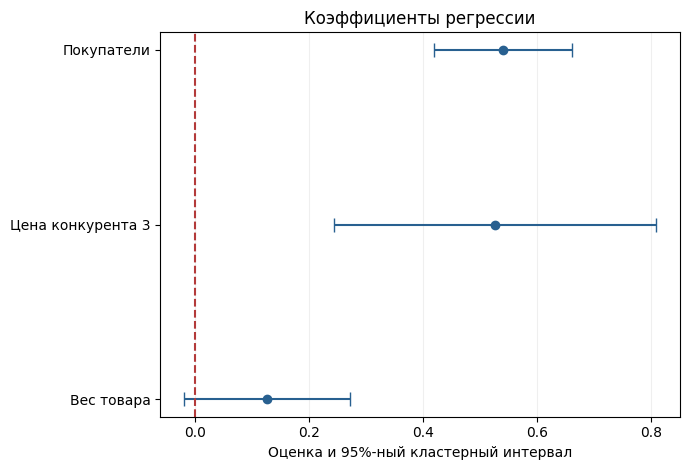

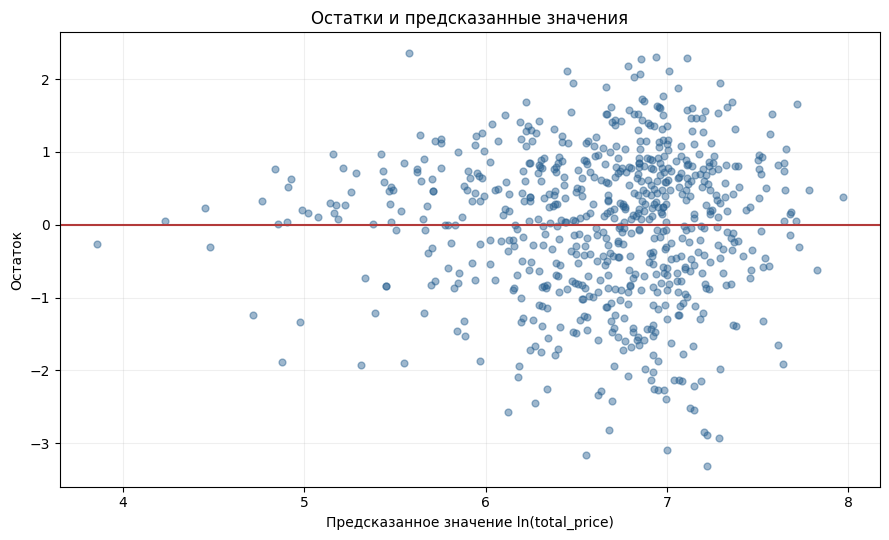

In [7]:
coefficient_labels = ['Покупатели', 'Цена конкурента 3', 'Вес товара']
coefficient_values = cluster_result.params[1:]
coefficient_intervals = confidence_intervals[1:]
positions = np.arange(len(coefficient_values))
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.errorbar(
    coefficient_values,
    positions,
    xerr=np.vstack([
        coefficient_values - coefficient_intervals[:, 0],
        coefficient_intervals[:, 1] - coefficient_values,
    ]),
    fmt='o',
    capsize=5,
    color='#286090',
    ecolor='#286090',
)
ax.axvline(0, color='#b33a3a', linestyle='--', linewidth=1.5)
ax.set_yticks(positions, labels=coefficient_labels)
ax.invert_yaxis()
ax.set_xlabel('Оценка и 95%-ный кластерный интервал')
ax.set_title('Коэффициенты регрессии')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig('coefficients_ci_simple.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(ols_result.fittedvalues, ols_result.resid, alpha=0.45, color='#286090', s=24)
ax.axhline(0, color='#b33a3a', linewidth=1.5)
ax.set_title('Остатки и предсказанные значения')
ax.set_xlabel('Предсказанное значение ln(total_price)')
ax.set_ylabel('Остаток')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig('residuals_simple.png', dpi=160, bbox_inches='tight')
plt.show()